# Chapter 4: Trees, forests and groups

*Trees, ensembles, clustering: used, compared, not derived · also searched as: decision tree, random
forest, gradient boosting, k-means clustering*

**By the end you can** read a small tree, say what a forest and a booster do to a tree's weakness,
count what each costs to explain, and run k-means once. Internals and maths come later. All numbers
here are invented.

In [1]:
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 11, "axes.titleweight": "bold"})
INK, VIOLET, ROSE, GREEN, MUTED = "#1A0F5C", "#5B3FD6", "#D63A6A", "#1F8A5B", "#6B6690"

def check(label, ok):
    """Print PASS or FAIL on one line, so a reader sees at a glance whether a step worked."""
    print(("PASS  " if ok else "FAIL  ") + label)

print("Charts and the check() helper are ready.")

Charts and the check() helper are ready.


## A tree is a game of twenty questions

Twelve invented Kalpa customers: visits a month, average basket in Rs, and whether they joined the
loyalty plan. Predict the first question the tree asks.

|--- basket_rs <= 525.00
|   |--- class: 0
|--- basket_rs >  525.00
|   |--- visits <= 2.50
|   |   |--- class: 0
|   |--- visits >  2.50
|   |   |--- class: 1



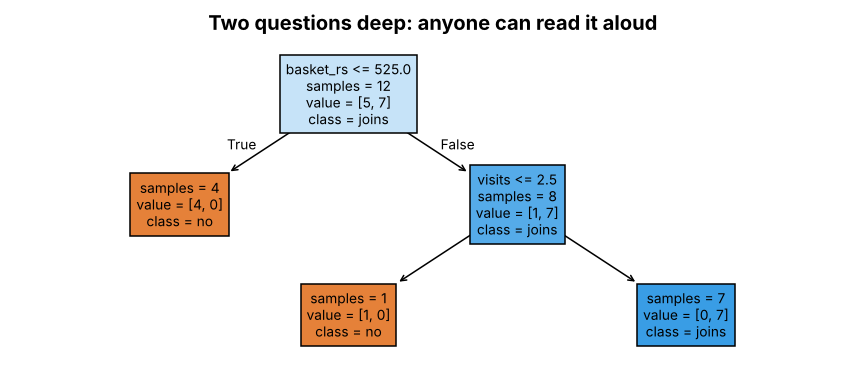

In [2]:
import numpy as np, pandas as pd
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
shop = pd.DataFrame({"visits": [1, 2, 2, 3, 4, 4, 5, 6, 6, 7, 8, 9],
                     "basket_rs": [300, 900, 450, 1200, 350, 800, 1500, 400, 1100, 950, 600, 1300],
                     "joined": [0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1]})
F = ["visits", "basket_rs"]
tree = DecisionTreeClassifier(max_depth=2, random_state=0).fit(shop[F], shop["joined"])
print(export_text(tree, feature_names=F))
fig, ax = plt.subplots(figsize=(8, 3.6))
plot_tree(tree, feature_names=F, class_names=["no", "joins"], filled=True, impurity=False, fontsize=9, ax=ax)
ax.set_title("Two questions deep: anyone can read it aloud"); plt.tight_layout(); plt.show()

## A forest votes; a booster corrects

A **random forest** grows many trees, each on a resampled set of customers and columns, and lets them
vote. The vote averages away the wobble one deep tree has. A **booster** grows small trees in a chain,
each aimed at the customers the chain so far gets wrong. You use both today; their insides come later.

In [3]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
forest = RandomForestClassifier(n_estimators=5, max_depth=2, random_state=3).fit(shop[F], shop["joined"])
newcomer = pd.DataFrame({"visits": [7], "basket_rs": [1000]})
votes = [int(t.predict(newcomer.values)[0]) for t in forest.estimators_]
print("one tree says:", "joins" if tree.predict(newcomer)[0] else "no")
print("five forest trees vote on the newcomer (7 visits, Rs 1,000 basket):", votes,
      "-> forest says", "joins" if forest.predict(newcomer)[0] else "no")

boost = GradientBoostingClassifier(n_estimators=4, max_depth=1, learning_rate=1.0, random_state=0)
boost.fit(shop[F], shop["joined"])
wrong = [int((p != shop["joined"]).sum()) for p in boost.staged_predict(shop[F])]
print("customers the booster still gets wrong after rounds 1, 2, 3, 4:", wrong)

one tree says: joins
five forest trees vote on the newcomer (7 visits, Rs 1,000 basket): [0, 1, 1, 1, 1] -> forest says joins
customers the booster still gets wrong after rounds 1, 2, 3, 4: [1, 0, 0, 0]


         model  final answers to explain
      one tree                         3
 forest of 100                       280
booster of 100                       200


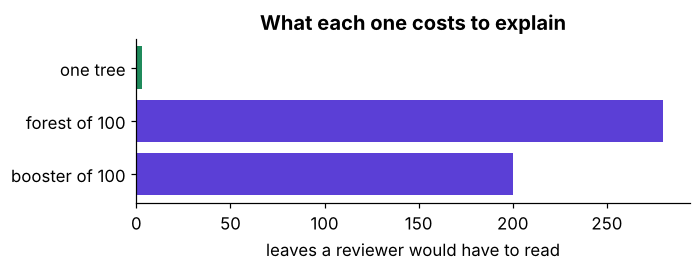

PASS  the booster's mistakes never rise round by round
PASS  a forest has far more leaves to read than one tree


In [4]:
cost = pd.DataFrame({"model": ["one tree", "forest of 100", "booster of 100"],
                     "final answers to explain": [tree.get_n_leaves(),
                         sum(t.get_n_leaves() for t in RandomForestClassifier(100, max_depth=2, random_state=0)
                             .fit(shop[F], shop["joined"]).estimators_),
                         100 * 2]})        # 100 one-question trees, two leaves each
print(cost.to_string(index=False))
fig, ax = plt.subplots(figsize=(6.5, 2.6))
ax.barh(cost["model"], cost["final answers to explain"], color=[GREEN, VIOLET, VIOLET])
ax.set_xlabel("leaves a reviewer would have to read"); ax.invert_yaxis()
ax.set_title("What each one costs to explain"); plt.tight_layout(); plt.show()
check("the booster's mistakes never rise round by round", all(b <= a for a, b in zip(wrong, wrong[1:])))
check("a forest has far more leaves to read than one tree", cost.iloc[1, 1] > 10 * cost.iloc[0, 1])

## Groups without an answer column: clustering, in one cell

k-means puts customers into k groups by distance, with no "joined" column at all. Marketing uses it to
name segments; it predicts nothing.

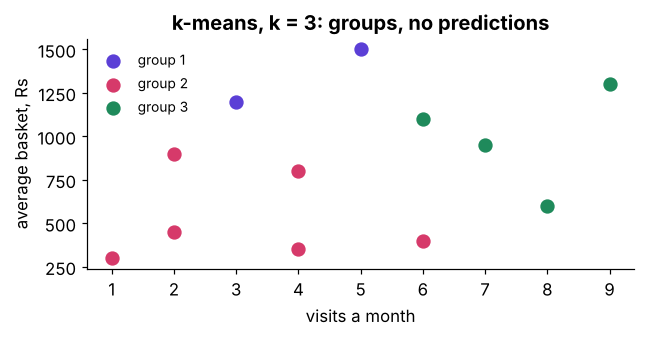

PASS  k-means placed all twelve customers in three groups


In [5]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
Z = StandardScaler().fit_transform(shop[F])
groups = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(Z)
fig, ax = plt.subplots(figsize=(6, 3.2))
for g, colour in zip(range(3), [VIOLET, ROSE, GREEN]):
    pts = shop[groups == g]
    ax.scatter(pts["visits"], pts["basket_rs"], s=70, color=colour, label=f"group {g + 1}")
ax.set_xlabel("visits a month"); ax.set_ylabel("average basket, Rs")
ax.legend(frameon=False, fontsize=9); ax.set_title("k-means, k = 3: groups, no predictions")
plt.tight_layout(); plt.show()
check("k-means placed all twelve customers in three groups", len(set(groups)) == 3 and len(groups) == 12)

## Carry this

| Tool | Reach for it when | Watch out |
|---|---|---|
| One tree | a committee must read the rule | deep trees memorise (case 1) |
| Random forest | one tree wobbles and you can afford many | it still has to beat the baseline and the simple model |
| Gradient boosting | the last points of ranking pay | more to monitor and explain; tune with folds |
| k-means | you need segments and have no answer column | it groups; it never predicts |
| Logistic regression | you need probabilities a cost rule can trust | it misses interactions you do not build |

Ensemble internals, boosting mathematics and search frameworks wait for the tentative IITGN faculty session.